In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

matplotlib.rcParams['figure.dpi'] = 100

In [2]:
ROOT_DIR = Path("..").resolve()
sys.path.append(str(ROOT_DIR))

In [3]:
from src.preprocessing import build_preprocessor

PATH_DATA = ROOT_DIR / "data" / "silver level" / "dados_calibrados"

# Silver guarda só RAW calibrado; as variantes de pré-processamento são
# computadas ON-THE-FLY abaixo (apenas para esta visualização).
# Nota: "RAW (calibrado)" NÃO é o dado bruto do sensor — é o dado APÓS
# calibração radiométrica (white/dark), remoção das 15 primeiras/últimas
# bandas e seleção da ROI (Hough). É a linha de base de comparação.
df_raw = pd.read_csv(PATH_DATA / "master_raw.csv")

# label de exibição → chave do build_preprocessor
METODOS = {
    "RAW (calibrado)": "raw",
    "MSC":             "msc",
    "SavGol":          "savigol",
    "Z-Score":         "z_score",
}
CORES = {
    "RAW (calibrado)": "#2196F3",
    "MSC":             "#4CAF50",
    "SavGol":          "#FF9800",
    "Z-Score":         "#9C27B0",
}

In [4]:
band_cols = [c for c in df_raw.columns if c not in ("sample_id", "target")]
SAMPLE_ID_ALVO = "426_1_240506-160058"   # amostra com melhor detecção de ROI (círculo mais preciso)
sample_id = SAMPLE_ID_ALVO if SAMPLE_ID_ALVO in df_raw["sample_id"].values else df_raw["sample_id"].iloc[0]

df_s  = df_raw[df_raw["sample_id"] == sample_id]
X_raw = df_s[band_cols].values
y     = df_s["target"].values

# Aplica cada pré-processamento ON-THE-FLY aos pixels desta amostra (viz)
datasets_pre = {}
for label, metodo in METODOS.items():
    Xp = build_preprocessor(metodo).fit_transform(X_raw)
    datasets_pre[label] = (pd.DataFrame(Xp, columns=band_cols), y)

# Comprimentos de onda reais em nm (SisuCHEMA SWIR 1000–2500 nm, 226 bandas
# após remoção das bordas; mapeamento linear índice 0→1000, 225→2500 nm).
N_BANDAS = len(band_cols)
WL_MIN, WL_MAX = 1000.0, 2500.0
wavelengths = [WL_MIN + i * (WL_MAX - WL_MIN) / (N_BANDAS - 1)
               for i in range(N_BANDAS)]

print(f"Amostra: {sample_id}")
print(f"Bandas: {len(band_cols)} ({wavelengths[0]:.0f}–{wavelengths[-1]:.0f} nm)")
print(f"Pixels: {X_raw.shape[0]}")

Amostra: 426_1_240506-160058
Bandas: 226 (1000–2500 nm)
Pixels: 19109


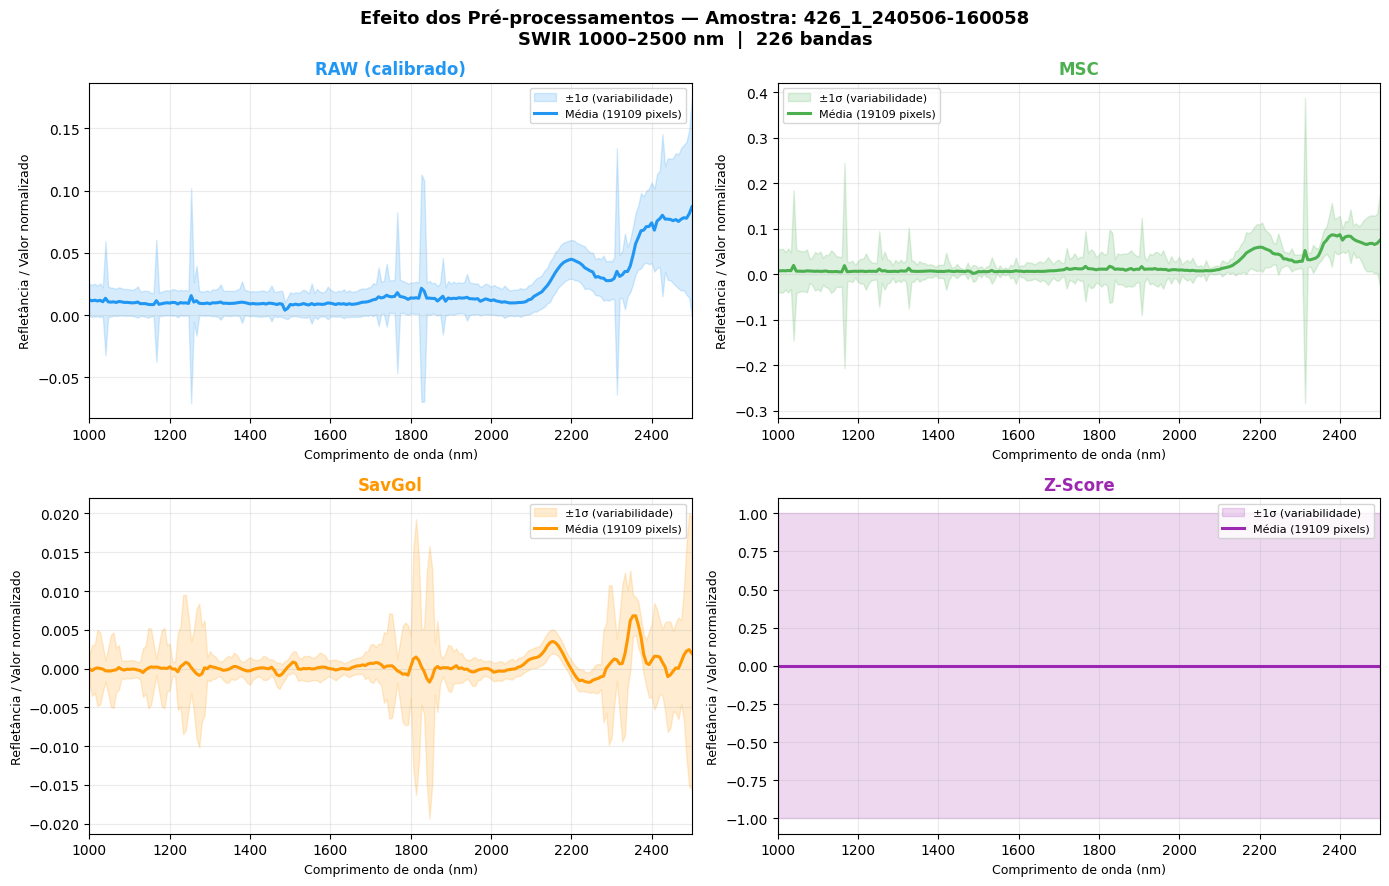

Figura salva: preprocessamentos_separados.png


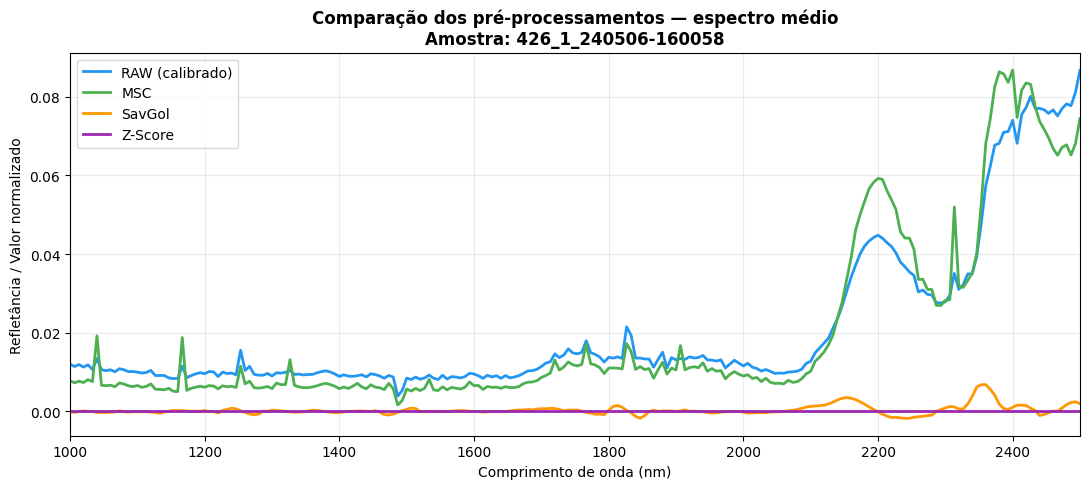

Figura salva: preprocessamentos_sobrepostos.png


In [5]:
# ── 4 gráficos separados — um por pré-processamento ──────────────────────────
# Cada gráfico mostra o espectro médio + banda de desvio padrão (±1σ).
# Eixo X em nm reais. RAW (calibrado) é a referência.

OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    f"Efeito dos Pré-processamentos — Amostra: {sample_id}\n"
    f"SWIR {wavelengths[0]:.0f}–{wavelengths[-1]:.0f} nm  |  {len(band_cols)} bandas",
    fontsize=13, fontweight="bold"
)

for ax, (label, (X, y)) in zip(axes.flat, datasets_pre.items()):
    cor  = CORES[label]
    vals = X.values          # (N_pixels × N_bandas)

    media = vals.mean(axis=0)
    std   = vals.std(axis=0)

    # Banda de variabilidade ±1σ (substitui os pixels individuais — muito mais limpo)
    ax.fill_between(wavelengths, media - std, media + std,
                    color=cor, alpha=0.18, label="±1σ (variabilidade)")

    # Espectro médio em destaque
    ax.plot(wavelengths, media, color=cor, linewidth=2.2,
            label=f"Média ({len(vals)} pixels)")

    ax.set_title(label, fontsize=12, fontweight="bold", color=cor)
    ax.set_xlabel("Comprimento de onda (nm)", fontsize=9)
    ax.set_ylabel("Refletância / Valor normalizado", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.25)
    ax.set_xlim(wavelengths[0], wavelengths[-1])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "preprocessamentos_separados.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva: preprocessamentos_separados.png")

# ── Gráfico sobreposto para comparação direta ─────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(11, 5))
for label, (X, y) in datasets_pre.items():
    media = X.values.mean(axis=0)
    ax2.plot(wavelengths, media, color=CORES[label], linewidth=2, label=label)

ax2.set_title(
    f"Comparação dos pré-processamentos — espectro médio\n"
    f"Amostra: {sample_id}",
    fontsize=12, fontweight="bold"
)
ax2.set_xlabel("Comprimento de onda (nm)", fontsize=10)
ax2.set_ylabel("Refletância / Valor normalizado", fontsize=10)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.25)
ax2.set_xlim(wavelengths[0], wavelengths[-1])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "preprocessamentos_sobrepostos.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Figura salva: preprocessamentos_sobrepostos.png")